# EDA_0: Bank Marketing

**Projekt:** Priorisierung von Bankkontakten (DMI01 / DAN01 Data Analytics)
**Problemstellung:** Eine Bank kann in einer Festgeldkampagne nicht alle Kunden anrufen. Wen soll sie zuerst anrufen?
**Forschungsfrage:** Wie gut lässt sich ein Festgeldabschluss mit den Merkmalen vorhersagen, die vor einem Anruf bekannt sind?
**Daten:** Moro, Rita & Cortez (2014), UCI Bank Marketing, bank-additional-full.csv, https://doi.org/10.24432/C5K306, CC BY 4.0.

Aufbau wie im Kursbeispiel *EDA_0_Hotel_booking_data*: 1. Bibliotheken und Daten laden, 2. Übersicht, 3. Fehlende Werte, 4. Univariate Analyse, 5. Ausreißer, 6. Bivariate Analyse, 7. Behandlung fehlender Werte, 8. Transformationen und Speichern. Die Modellierung folgt in *Met_1_Klassifikation_Bank_Marketing*.

In [1]:
# Einmalig ausführen, falls Pakete fehlen:
# %pip install -r ../requirements.txt

## 1. Bibliotheken importieren und Daten laden

Erläuterung: Hier laden wir alle notwendigen Bibliotheken für die Analyse und Visualisierung sowie den Datensatz selbst. Der Pfad ist relativ zum Ordner *notebooks*, damit das Projekt auf jedem Rechner läuft.

In [2]:
# Import helpful packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

# Matplotlib setting for Jupyter Notebook
%matplotlib inline

In [3]:
plt.style.use('ggplot')

# Configuration
input = os.path.join("..", "data", "raw")  # relativer Pfad zum Rohdatenordner
INPUT_FILE = os.path.join(input, "bank-additional-full.csv")
IMAGE_DIR = os.path.join("..", "images")    # hier speichern wir Abbildungen für den Bericht

df_raw = pd.read_csv(INPUT_FILE, sep=";")  # die UCI-Datei ist mit Semikolon getrennt

## 2. Übersicht und grundlegende Informationen

Erläuterung: Diese Schritte geben einen ersten Überblick über den Datensatz, seine Struktur, Datentypen und die Zielvariable.

Gegen Data Leakage teilen wir die Daten vor der Analyse in Training (80 %) und Test (20 %). Die EDA schaut nur auf die Trainingsdaten. Die Aufteilung ist genau dieselbe wie später in *Met_1* (gleicher `random_state=42`, gleiche Schichtung nach *y*).

In [4]:
# Train/Test-Split VOR der Analyse (gleiche Einstellungen wie in Met_1)
df_eda, df_test_eda = train_test_split(
    df_raw,
    test_size=0.2,
    random_state=42,
    stratify=df_raw['y']  # gleicher Anteil 'yes' in Training und Test
)

# Erste und letzte Zeilen anzeigen
print("Erste 5 Zeilen des Trainingsdatensatzes:")
display(df_eda.head())
print("\nLetzte 5 Zeilen des Trainingsdatensatzes:")
display(df_eda.tail())

# Grundlegende Informationen
print("\nGrundlegende Informationen:")
df_eda.info()

# Separate Listen für numerische und kategoriale Spalten erstellen
numeric_columns = df_eda.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df_eda.select_dtypes(exclude=['number']).columns.tolist()

print(f"\nNumerische Spalten ({len(numeric_columns)}): {numeric_columns}")
print(f"Kategoriale Spalten ({len(categorical_columns)}): {categorical_columns}")

# Größe des Datensatzes
print(f"\nGesamter Datensatz: {df_raw.shape[0]} Zeilen, Training (EDA): {df_eda.shape[0]}, Test: {df_test_eda.shape[0]}")
print(f"Anteil Abschlüsse (y = yes) im Training: {(df_eda['y'] == 'yes').mean():.2%}")

Erste 5 Zeilen des Trainingsdatensatzes:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
25611,49,blue-collar,married,basic.9y,unknown,no,no,cellular,nov,wed,...,4,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no
26010,37,entrepreneur,married,university.degree,no,no,no,telephone,nov,wed,...,2,999,1,failure,-0.1,93.200,-42.0,4.120,5195.8,no
40194,78,retired,married,basic.4y,no,no,no,cellular,jul,mon,...,1,999,0,nonexistent,-1.7,94.215,-40.3,0.870,4991.6,yes
297,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
36344,59,retired,divorced,university.degree,no,no,no,cellular,jun,tue,...,2,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,no



Letzte 5 Zeilen des Trainingsdatensatzes:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
40205,28,services,single,high.school,no,yes,no,cellular,jul,tue,...,1,999,0,nonexistent,-1.7,94.215,-40.3,0.876,4991.6,no
27316,52,technician,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,1,failure,-0.1,93.200,-42.0,4.021,5195.8,no
14392,54,admin.,married,basic.9y,no,no,yes,cellular,jul,mon,...,4,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
7494,29,admin.,married,university.degree,no,no,no,telephone,may,fri,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.864,5191.0,no
10747,35,admin.,married,university.degree,no,no,yes,telephone,jun,tue,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,no



Grundlegende Informationen:
<class 'pandas.core.frame.DataFrame'>
Index: 32950 entries, 25611 to 10747
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             32950 non-null  int64  
 1   job             32950 non-null  object 
 2   marital         32950 non-null  object 
 3   education       32950 non-null  object 
 4   default         32950 non-null  object 
 5   housing         32950 non-null  object 
 6   loan            32950 non-null  object 
 7   contact         32950 non-null  object 
 8   month           32950 non-null  object 
 9   day_of_week     32950 non-null  object 
 10  duration        32950 non-null  int64  
 11  campaign        32950 non-null  int64  
 12  pdays           32950 non-null  int64  
 13  previous        32950 non-null  int64  
 14  poutcome        32950 non-null  object 
 15  emp.var.rate    32950 non-null  float64
 16  cons.price.idx  32950 non-null  float64
 17  con

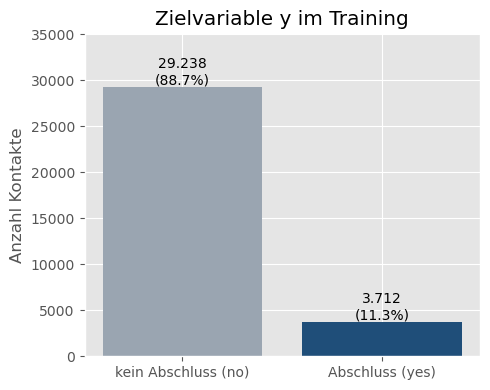

In [5]:
# Verteilung der Zielvariable (Training)
counts = df_eda['y'].value_counts()
plt.figure(figsize=(5, 4))
plt.bar(['kein Abschluss (no)', 'Abschluss (yes)'], [counts['no'], counts['yes']], color=['#9aa5b1', '#1f4e79'])
for i, v in enumerate([counts['no'], counts['yes']]):
    plt.text(i, v, f"{v:,}".replace(",", ".") + f"\n({v / len(df_eda):.1%})", ha='center', va='bottom')
plt.title('Zielvariable y im Training')
plt.ylabel('Anzahl Kontakte')
plt.ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig(os.path.join(IMAGE_DIR, "01_klassenverteilung.png"), dpi=150)
plt.show()

### Interpretation:

Der Datensatz hat 41.188 Kontakte mit 20 Merkmalen und der Zielvariable *y*. Im Training liegen 32.950 Zeilen, im Test 8.238. Nur 11,3 % der Kontakte enden mit einem Abschluss (3.712 von 32.950). Die Klassen sind also stark unausgewogen: Ein Modell, das immer „Nein“ sagt, hätte schon rund 89 % Accuracy und wäre trotzdem nutzlos. Darum brauchen wir später andere Maße (ROC-AUC, Recall, Precision).

## 3. Prüfung auf fehlende Werte

Erläuterung: Hier suchen wir fehlende Werte. Zusätzlich prüfen wir versteckte fehlende Angaben: die Kategorie "unknown" und den Code 999 bei *pdays*.

In [6]:
# Anzahl fehlender Werte (NaN)
missing_values = df_eda.isnull().sum()
print(f"Echte fehlende Zellen (NaN) im Training: {missing_values.sum()}")

# Versteckte fehlende Werte: Kategorie 'unknown'
unknown_counts = (df_eda[categorical_columns] == "unknown").sum()
unknown_info = pd.DataFrame({
    'unknown': unknown_counts,
    'Prozent (%)': (unknown_counts / len(df_eda) * 100).round(2)
})
unknown_info = unknown_info[unknown_info['unknown'] > 0].sort_values('Prozent (%)', ascending=False)
print("\nAnzahl 'unknown' pro Spalte:")
display(unknown_info)

# Code 999 bei pdays = kein früherer Kontakt (laut Datenbeschreibung)
print(f"pdays = 999 (nie kontaktiert): {(df_eda['pdays'] == 999).mean():.2%} der Trainingszeilen")

Echte fehlende Zellen (NaN) im Training: 0

Anzahl 'unknown' pro Spalte:


,unknown,Prozent (%)
default,6940,21.06
education,1397,4.24
housing,796,2.42
loan,796,2.42
job,265,0.80
marital,65,0.20


pdays = 999 (nie kontaktiert): 96.28% der Trainingszeilen


### Interpretation:

Es gibt keine leeren Zellen, aber versteckte Lücken: Bei *default* steht 6.940-mal "unknown" (21 %), bei *education* 1.397-mal, bei *housing* und *loan* je 796-mal. Bei *pdays* steht in 96 % der Fälle der Code 999 (nie kontaktiert). Diese Werte behandeln wir in Abschnitt 7.

## 4. Univariate Analyse - Verteilungen einzelner Variablen

Erläuterung: Diese Grafiken zeigen die Verteilung jeder einzelnen Variable. Histogramme zeigen die Form der Verteilung, Boxplots zeigen Ausreißer.

Statistische Zusammenfassung numerischer Spalten:


,count,mean,std,min,25%,50%,75%,max
age,32950.0,40.014112,10.403636,17.000,32.000,38.000,47.000,98.000
duration,32950.0,258.127466,258.975917,0.000,103.000,180.000,319.000,4918.000
campaign,32950.0,2.560607,2.752326,1.000,1.000,2.000,3.000,56.000
pdays,32950.0,962.052413,187.951096,0.000,999.000,999.000,999.000,999.000
previous,32950.0,0.174719,0.499025,0.000,0.000,0.000,0.000,7.000
emp.var.rate,32950.0,0.080470,1.571266,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,32950.0,93.575881,0.579209,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,32950.0,-40.508489,4.628223,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,32950.0,3.618395,1.735896,0.634,1.344,4.857,4.961,5.045
nr.employed,32950.0,5166.899651,72.434812,4963.600,5099.100,5191.000,5228.100,5228.100



Häufigkeitsverteilungen kategorialer Spalten:

job:


job
admin.           8314
blue-collar      7441
technician       5400
services         3196
management       2345
retired          1366
entrepreneur     1160
self-employed    1099
housemaid         855
unemployed        798
Name: count, dtype: int64

Anzahl eindeutiger Werte: 12

marital:


marital
married     19953
single       9257
divorced     3675
unknown        65
Name: count, dtype: int64

... (15 outputs left out)

poutcome
nonexistent    28416
failure         3429
success         1105
Name: count, dtype: int64

Anzahl eindeutiger Werte: 3

y:


y
no     29238
yes     3712
Name: count, dtype: int64

Anzahl eindeutiger Werte: 2


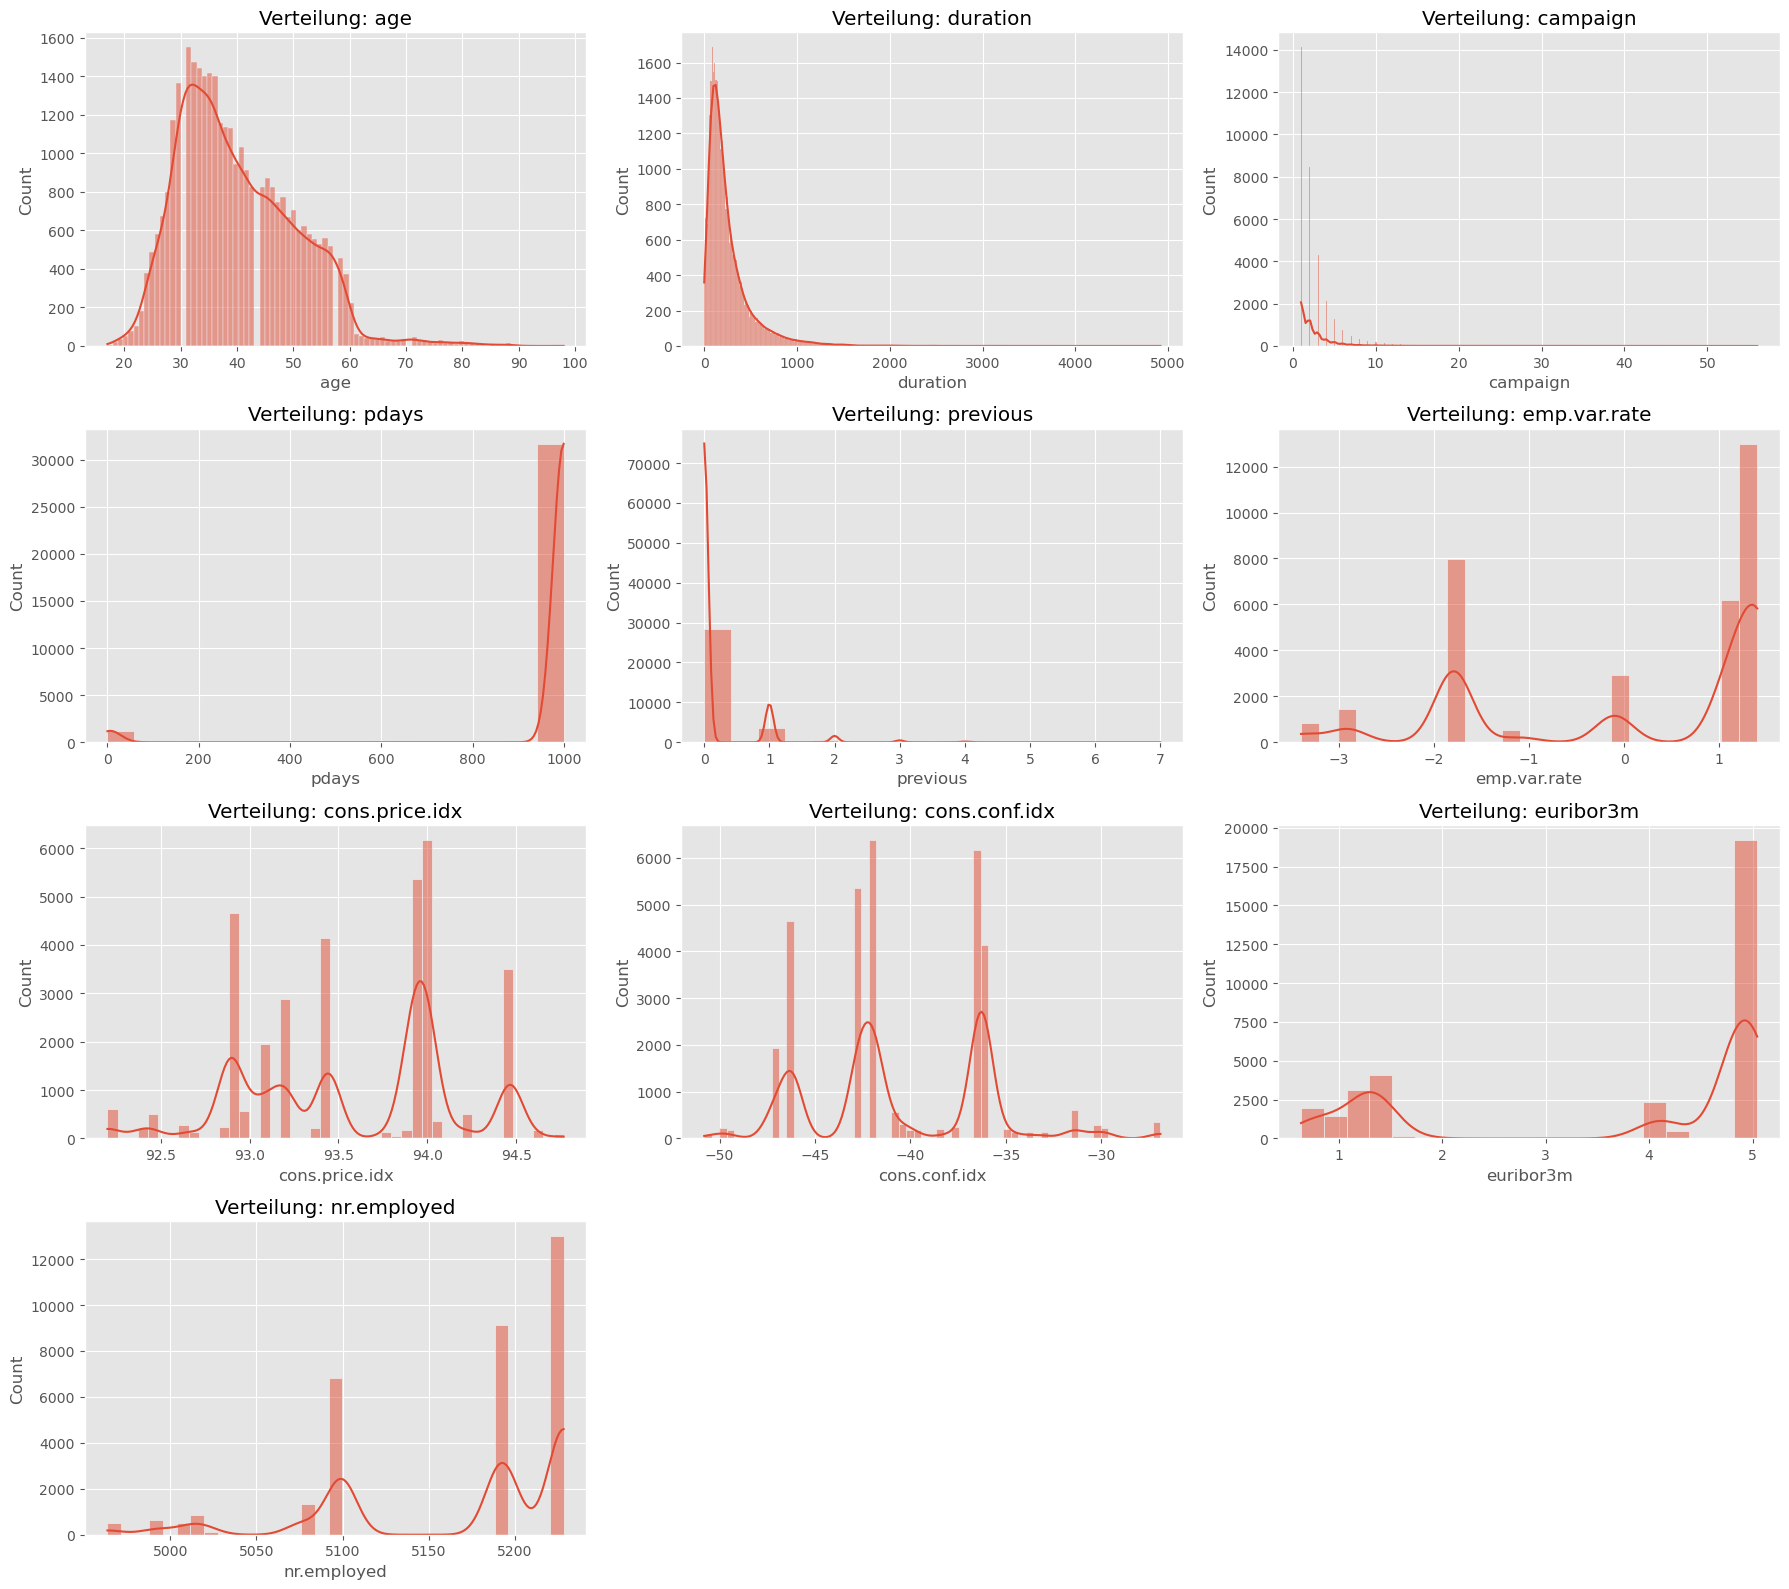

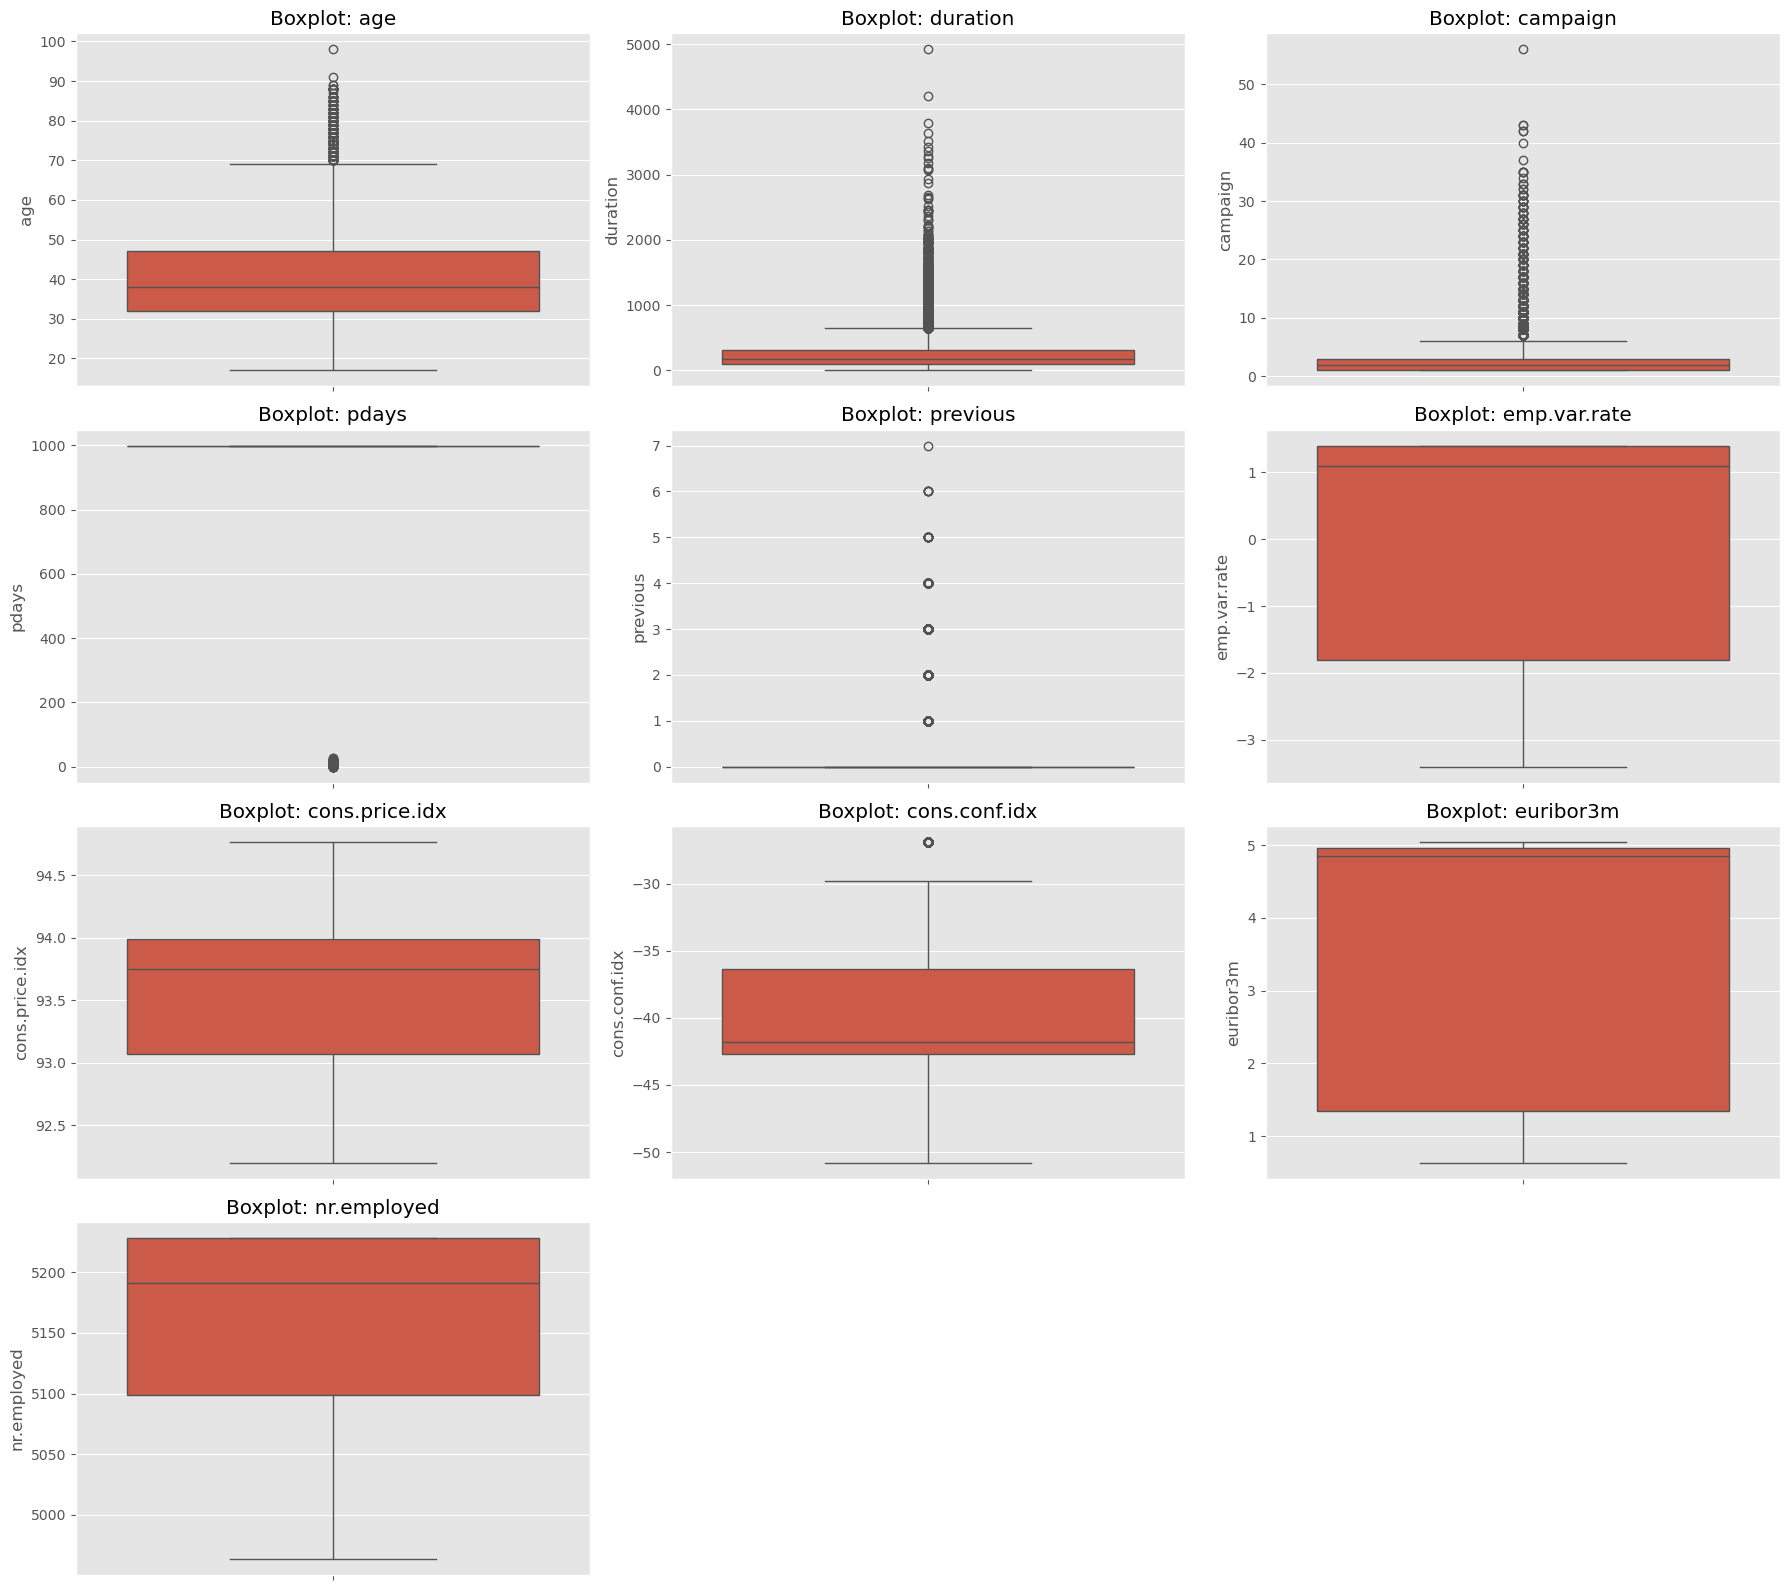

In [7]:
# Statistische Zusammenfassung für numerische Spalten
print("Statistische Zusammenfassung numerischer Spalten:")
display(df_eda[numeric_columns].describe().T)

# Häufigkeitsverteilungen für kategoriale Spalten
print("\nHäufigkeitsverteilungen kategorialer Spalten:")
for col in categorical_columns:
    print(f"\n{col}:")
    display(df_eda[col].value_counts().head(10))  # Top 10 häufigste Werte
    print(f"Anzahl eindeutiger Werte: {df_eda[col].nunique()}")

# Histogramme und Dichteplots für numerische Variablen
rows = int(np.ceil(len(numeric_columns) / 3))
plt.figure(figsize=(18, rows * 4))
for i, column in enumerate(numeric_columns):
    plt.subplot(rows, 3, i + 1)
    sns.histplot(df_eda[column], kde=True)
    plt.title(f'Verteilung: {column}')
plt.tight_layout()
plt.show()

# Box-Plots für numerische Variablen
plt.figure(figsize=(18, rows * 4))
for i, column in enumerate(numeric_columns):
    plt.subplot(rows, 3, i + 1)
    sns.boxplot(y=df_eda[column])
    plt.title(f'Boxplot: {column}')
plt.tight_layout()
plt.show()

### Interpretation:

Das Alter liegt zwischen 17 und 98 Jahren (Median 38). *campaign* (Anzahl Anrufe in dieser Kampagne) ist stark rechtsschief mit bis zu 56 Versuchen. *previous* ist fast immer 0. Die Wirtschaftszahlen (*emp.var.rate*, *euribor3m*, *nr.employed*) haben nur wenige verschiedene Werte, weil sie für ganze Zeiträume gelten. *duration* ist erst nach dem Anruf bekannt; wir beschreiben sie nur und nehmen sie nicht ins Modell.

## 5. Ausreißeranalyse

Erläuterung: Hier suchen wir Ausreißer mit zwei Methoden aus dem Kurs: Z-Score und IQR-Methode.

In [8]:
z_scores = pd.DataFrame(index=df_eda.index)  # gleiche Zeilen wie df_eda

for column in numeric_columns:
    # Im Bankdatensatz gibt es keine NaN, daher direkt berechnen
    z_scores[column] = np.abs(stats.zscore(df_eda[column]))

# Ausreißer identifizieren (|z| > 3)
print("Anzahl der Ausreißer pro numerischer Spalte (|z| > 3):")
display((z_scores > 3).sum())

# IQR-Methode
outliers_count = {}
for column in numeric_columns:
    Q1 = df_eda[column].quantile(0.25)
    Q3 = df_eda[column].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df_eda[column] < (Q1 - 1.5 * IQR)) | (df_eda[column] > (Q3 + 1.5 * IQR))).sum()
    outliers_count[column] = outliers

print("\nAnzahl der Ausreißer pro numerischer Spalte (IQR-Methode):")
display(pd.Series(outliers_count))

Anzahl der Ausreißer pro numerischer Spalte (|z| > 3):


age                286
duration           672
campaign           687
pdays             1226
previous           861
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
dtype: int64


Anzahl der Ausreißer pro numerischer Spalte (IQR-Methode):


age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64

### Interpretation:

Beide Methoden finden Ausreißer vor allem bei *campaign*, *previous* und *pdays*. Bei *pdays* kommen sie nur vom Code 999, bei *previous* von den vielen Nullen. Viele Anrufversuche oder ein Alter von 98 Jahren sind echte, mögliche Fälle. Entscheidung: Wir markieren Ausreißer, löschen sie aber nicht. Baummodelle kommen gut mit ihnen zurecht.

## 6. Bivariate Analyse - Mit Berücksichtigung verschiedener Datentypen

Erläuterung: Wir betrachten Zusammenhänge zwischen numerischen Variablen (Spearman-Korrelation, weil viele Variablen schief sind) und die Abschlussquote je Kategorie.

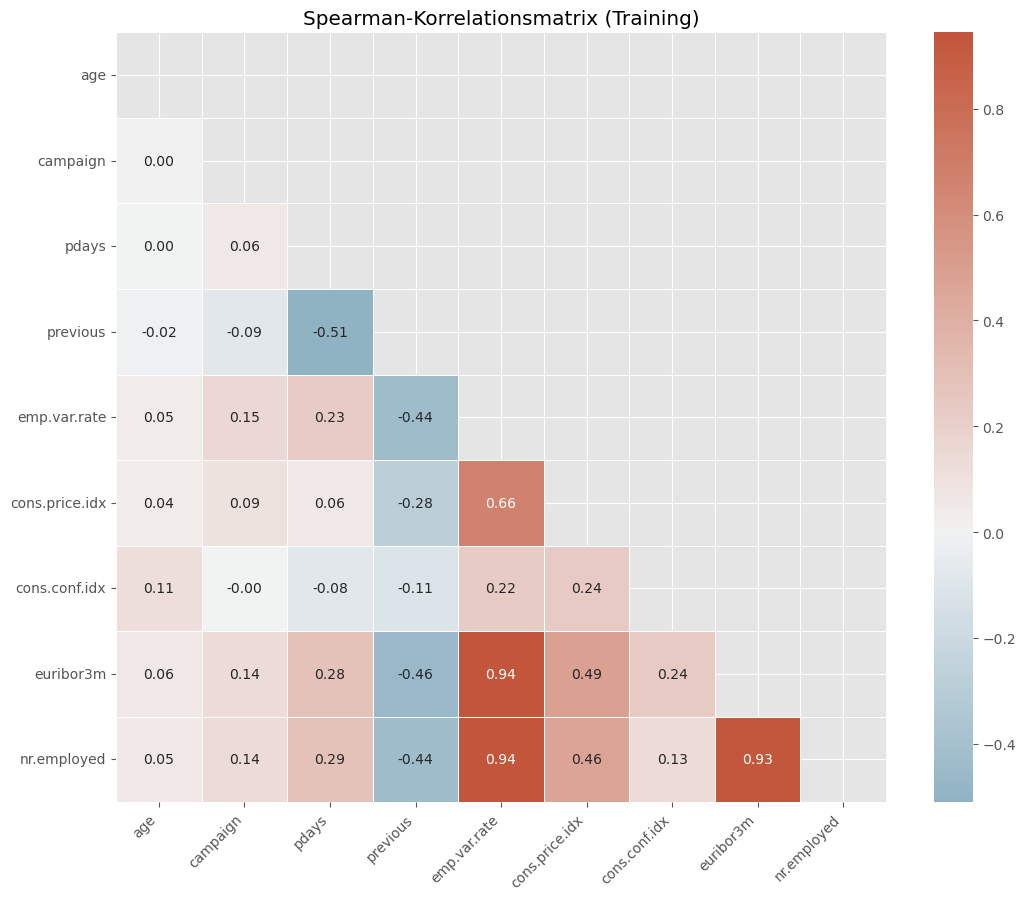

Top 6 stärkste Korrelationen:


emp.var.rate    nr.employed       0.944571
                euribor3m         0.939368
euribor3m       nr.employed       0.929028
emp.var.rate    cons.price.idx    0.664132
pdays           previous          0.510682
cons.price.idx  euribor3m         0.488893
dtype: float64

In [9]:
# Korrelation zwischen numerischen Variablen (ohne duration, da erst nach dem Anruf bekannt)
num_for_corr = [c for c in numeric_columns if c != 'duration']
corr_matrix = df_eda[num_for_corr].corr(method='spearman')

plt.figure(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, annot=True, fmt='.2f', square=True, linewidths=.5, center=0)
plt.title('Spearman-Korrelationsmatrix (Training)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Top stärkste Korrelationen
corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), 1).astype(bool)).stack()
print("Top 6 stärkste Korrelationen:")
display(corr_pairs.abs().sort_values(ascending=False).head(6))

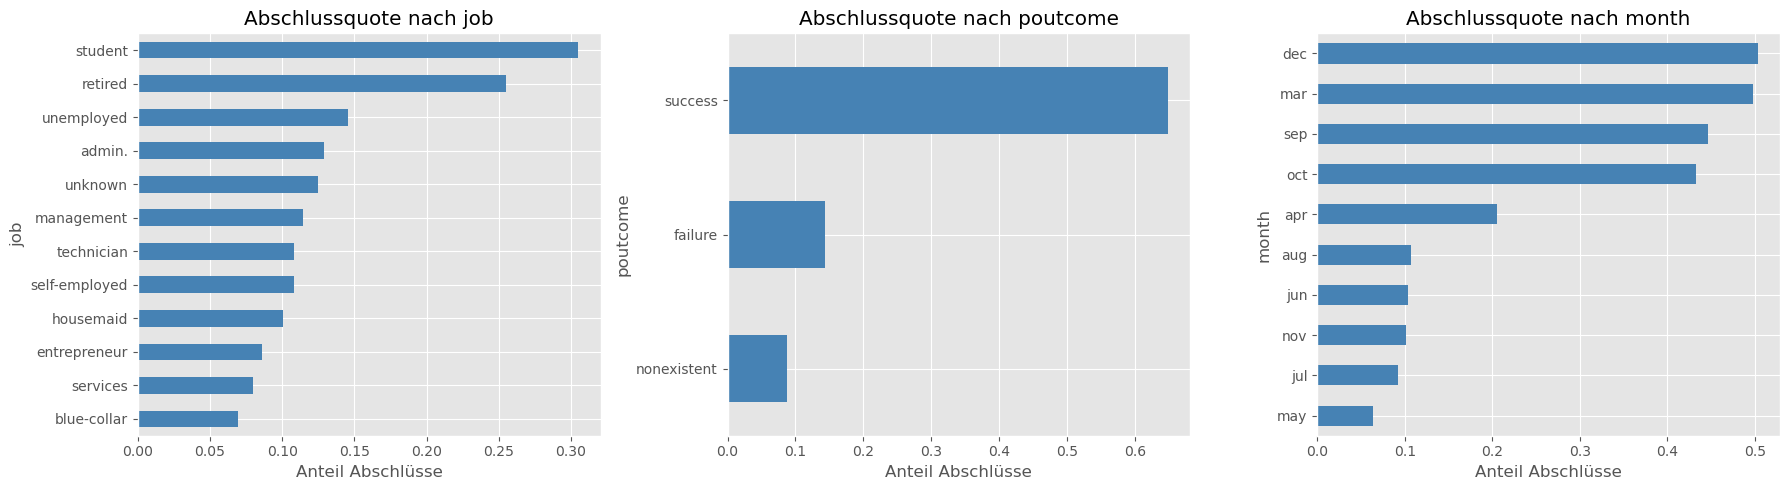

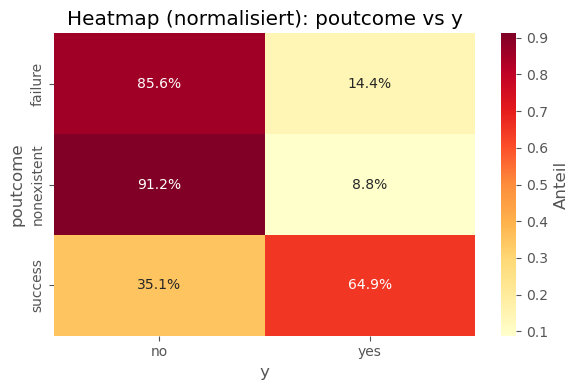

In [10]:
# Abschlussquote je Kategorie (Ziel 1 = yes)
target = (df_eda['y'] == 'yes').astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['job', 'poutcome', 'month']):
    rate = target.groupby(df_eda[col]).mean().sort_values()
    rate.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title(f'Abschlussquote nach {col}')
    ax.set_xlabel('Anteil Abschlüsse')
plt.tight_layout()
plt.show()

# Kreuztabelle und Heatmap für y und poutcome (Ergebnis der Vorkampagne)
ct_norm = pd.crosstab(df_eda['poutcome'], df_eda['y'], normalize='index')
plt.figure(figsize=(6, 4))
sns.heatmap(ct_norm, annot=True, fmt='.1%', cmap='YlOrRd', cbar_kws={'label': 'Anteil'})
plt.title('Heatmap (normalisiert): poutcome vs y')
plt.tight_layout()
plt.show()

### Interpretation:

Die Wirtschaftszahlen hängen sehr stark zusammen (Spearman bis 0,94 zwischen *emp.var.rate* und *nr.employed*, 0,93 zwischen *euribor3m* und *nr.employed*). Sie beschreiben zusammen die Wirtschaftslage eines Zeitraums. Die Abschlussquote unterscheidet sich deutlich: Wer in der letzten Kampagne abgeschlossen hat (*poutcome = success*), sagt zu 65 % wieder Ja, ohne Vorkontakt nur zu 9 %. Studierende (31 %) und Rentner (26 %) schließen öfter ab, Arbeiter (7 %) seltener. März, September, Oktober und Dezember haben hohe Quoten, aber nur wenige Anrufe. Das sind Zusammenhänge, keine Ursachen.

## 7. Behandlung fehlender Werte

Erläuterung: Hier legen wir fest, wie mit den versteckten fehlenden Werten umgegangen wird. Wir verwenden nur feste Regeln, die nichts aus den Daten lernen. Deshalb dürfen sie auf alle Zeilen angewendet werden, ohne dass Informationen aus dem Test ins Training gelangen.

In [11]:
df_processed = df_raw.copy()

# 'unknown' bleibt als eigene Kategorie erhalten (keine erfundenen Werte)
print("'unknown' bleibt Kategorie in:", unknown_info.index.tolist())

# pdays = 999 bedeutet 'nie kontaktiert' -> neues Ja/Nein-Merkmal statt der Zahl 999
df_processed['previously_contacted'] = (df_processed['pdays'] != 999).astype(int)
df_processed.drop('pdays', axis=1, inplace=True)

print(df_processed['previously_contacted'].value_counts())

'unknown' bleibt Kategorie in: ['default', 'education', 'housing', 'loan', 'job', 'marital']
previously_contacted
0    39673
1     1515
Name: count, dtype: int64


### Interpretation:

Statt der Zahl 999 gibt es jetzt ein klares Ja/Nein-Merkmal *previously_contacted* (1.515 von 41.188 Kontakten wurden schon früher angerufen). Die Kategorie "unknown" bleibt sichtbar, weil sie selbst eine Information ist. Beide Regeln sind fest und lernen nichts aus den Daten, deshalb gibt es kein Leakage.

## 8. Weitere Analysen und Transformationen

Erläuterung: Zum Schluss prüfen wir die Schiefe der numerischen Variablen, kodieren die Zielvariable als 0/1 und speichern den aufbereiteten Datensatz für die Modellierung.

In [12]:
# Analyse der Schiefe und Verteilungsformen numerischer Variablen (Training)
skewness = df_eda[numeric_columns].skew().sort_values(ascending=False)
kurtosis = df_eda[numeric_columns].kurtosis().sort_values(ascending=False)
distribution_stats = pd.DataFrame({'Schiefe': skewness, 'Kurtosis': kurtosis}).sort_values('Schiefe', ascending=False)
print("Verteilungsstatistiken (sortiert nach Schiefe):")
display(distribution_stats.round(2))

# Zielvariable als 0/1 kodieren
df_processed['y'] = df_processed['y'].map({'no': 0, 'yes': 1})

# Aufbereiteten Datensatz speichern (relativer Pfad)
output_file = os.path.join("..", "data", "processed", "bank_marketing_processed.csv")
df_processed.to_csv(output_file, index=False)
print(f"Data has been saved to {output_file} ({df_processed.shape[0]} Zeilen, {df_processed.shape[1]} Spalten)")

Verteilungsstatistiken (sortiert nach Schiefe):


,Schiefe,Kurtosis
campaign,4.74,36.97
previous,3.85,20.48
duration,3.33,21.45
age,0.76,0.67
cons.conf.idx,0.31,-0.35
cons.price.idx,-0.23,-0.83
euribor3m,-0.71,-1.41
emp.var.rate,-0.72,-1.07
nr.employed,-1.04,-0.01
pdays,-4.89,21.92


Data has been saved to ../data/processed/bank_marketing_processed.csv (41188 Zeilen, 21 Spalten)


### Interpretation:

*campaign*, *previous* und *duration* sind stark rechtsschief. Deshalb nutzen wir in der Modellierung vor allem Baumverfahren, die damit gut umgehen, und skalieren die Daten nur für die logistische Regression. Der gespeicherte Datensatz wird in *Met_1* eingelesen.